In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [12]:
df=pd.read_csv(r"/content/healthcare-dataset-stroke-data.csv")

In [13]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [14]:
df=df.drop('id',axis=1)

In [15]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   object 
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   object 
 5   work_type          5110 non-null   object 
 6   Residence_type     5110 non-null   object 
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                4909 non-null   float64
 9   smoking_status     5110 non-null   object 
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(3), object(5)
memory usage: 439.3+ KB


In [17]:
# null ------> (bmi)

In [18]:
df['stroke'].value_counts()

,count
stroke,
0,4861
1,249


In [19]:
df.describe()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [20]:
cols = list(df.nunique().sort_values().index[:7])
cols

['heart_disease',
 'hypertension',
 'Residence_type',
 'ever_married',
 'stroke',
 'gender',
 'smoking_status']

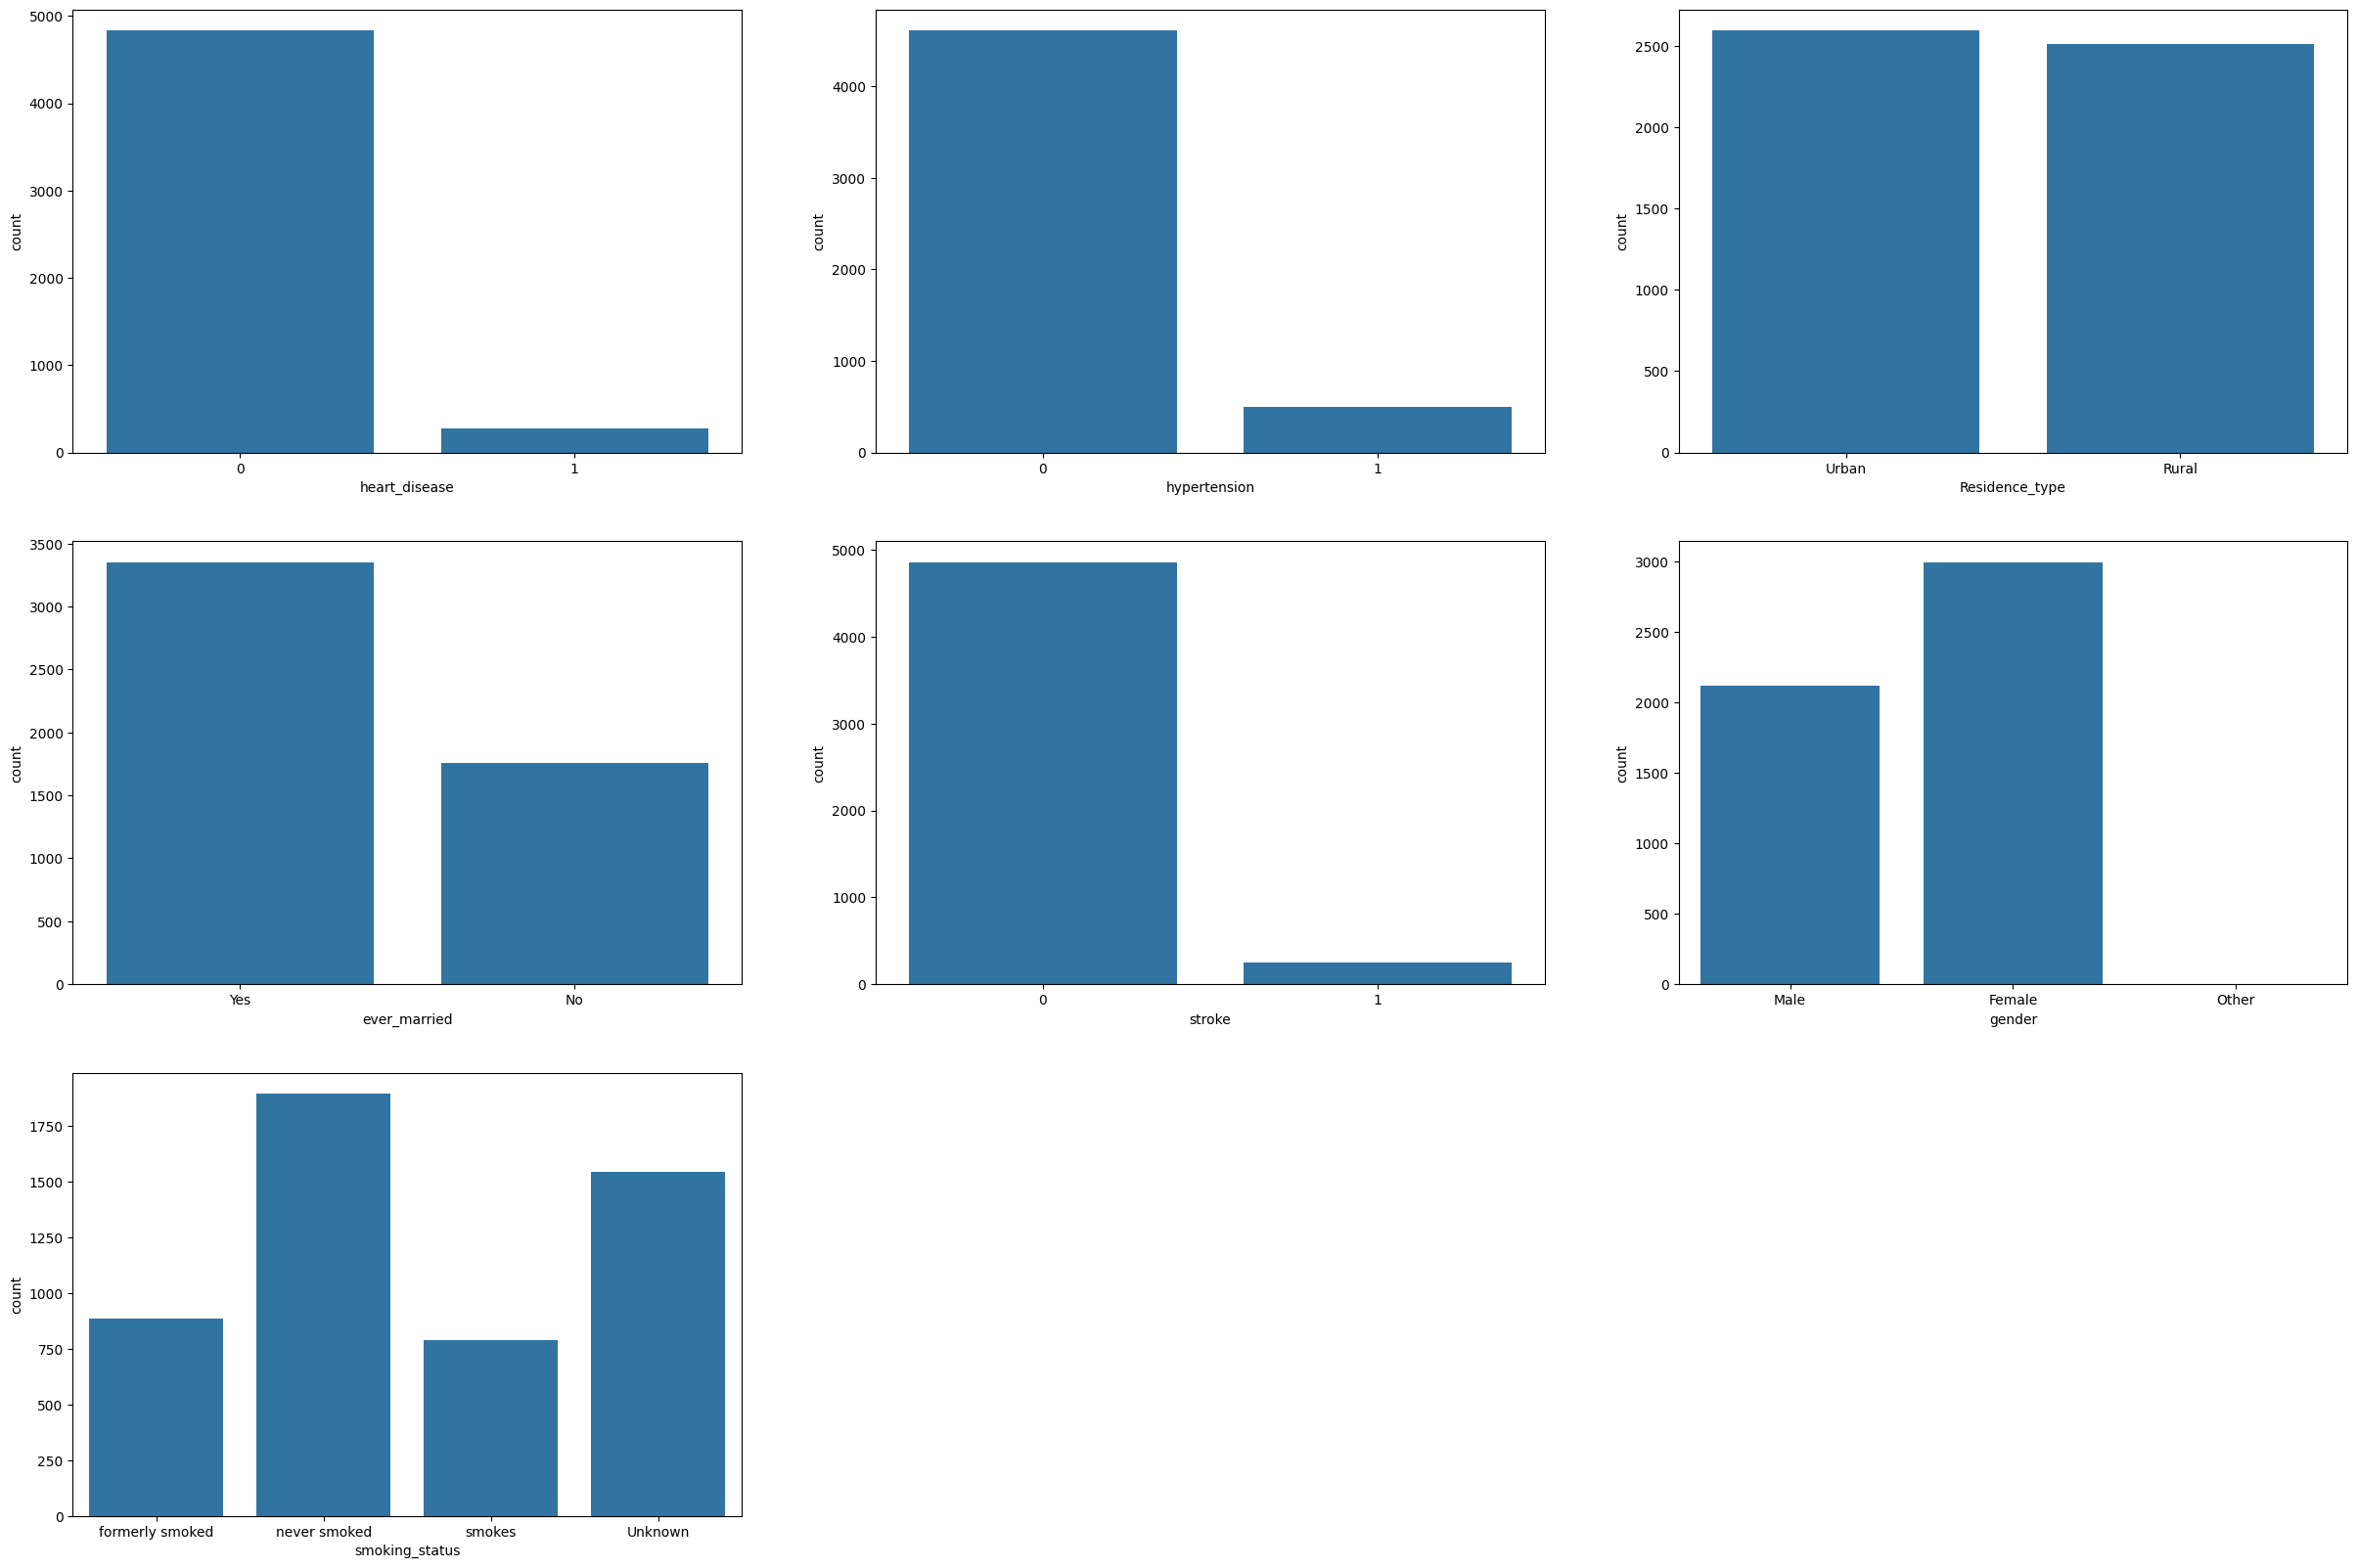

In [21]:
plt.figure(figsize=(30,20))
for n , col in enumerate(cols) :
    plt.subplot(3,3,n+1)
    sns.countplot(data=df,x=col)

In [22]:
df.shape

(5110, 11)

In [23]:
df.isna().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201
smoking_status,0


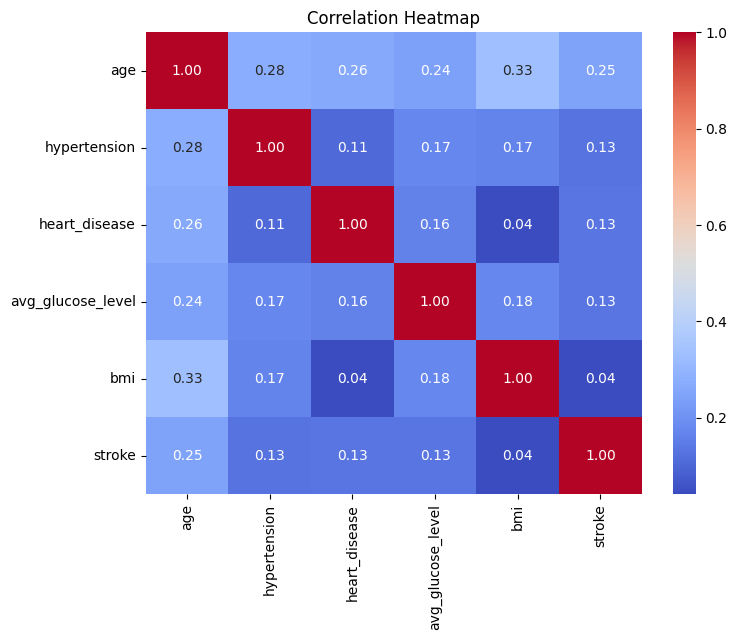

In [24]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

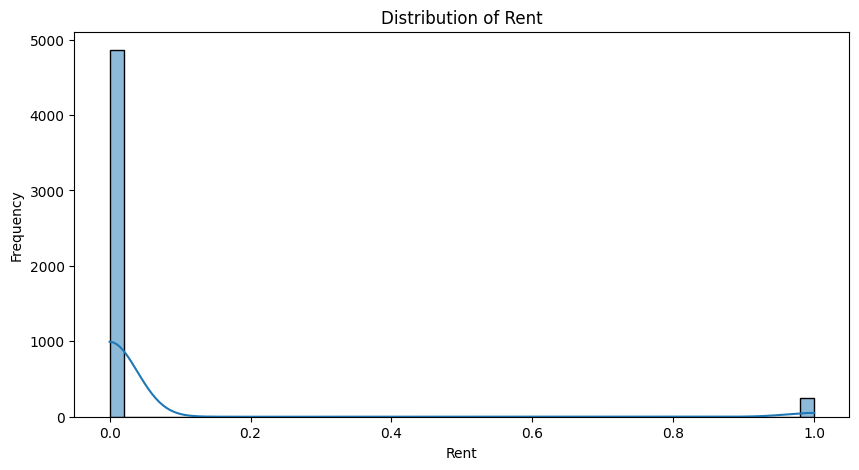

In [25]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='stroke', bins=50, kde=True)
plt.title('Distribution of Rent')
plt.xlabel('Rent')
plt.ylabel('Frequency')
plt.show()

<Axes: xlabel='bmi', ylabel='Count'>

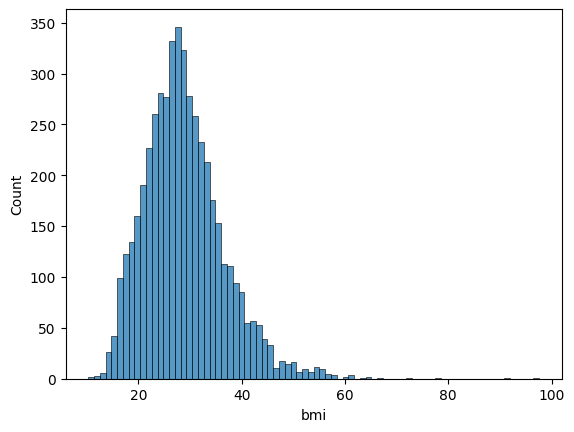

In [26]:
sns.histplot(df['bmi'])

In [27]:
df['bmi'].skew()

np.float64(1.0553402052962912)

(array([1, 2, 3, 4, 5, 6]),
 [Text(1, 0, 'age'),
  Text(2, 0, 'hypertension'),
  Text(3, 0, 'heart_disease'),
  Text(4, 0, 'avg_glucose_level'),
  Text(5, 0, 'bmi'),
  Text(6, 0, 'stroke')])

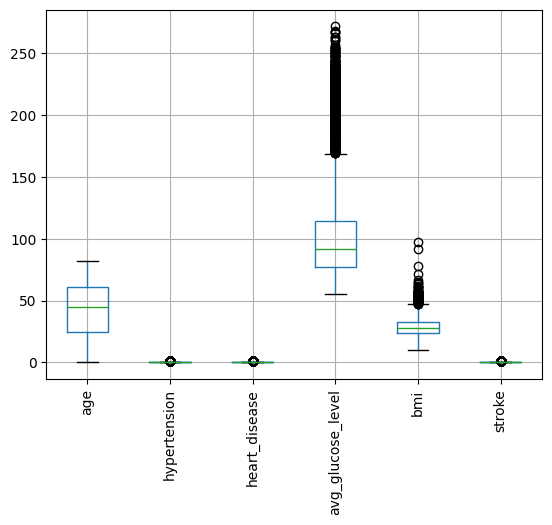

In [28]:
df.boxplot()
plt.xticks(rotation=90)

In [29]:
df.duplicated().sum()

np.int64(0)

In [30]:
df.nunique().sort_values()

,0
heart_disease,2
hypertension,2
Residence_type,2
ever_married,2
stroke,2
gender,3
smoking_status,4
work_type,5
age,104
bmi,418


In [31]:
df['gender'].unique()

array(['Male', 'Female', 'Other'], dtype=object)

In [32]:
df['gender'].value_counts()

,count
gender,
Female,2994
Male,2115
Other,1


In [33]:
df.drop(df[df['gender']=='Other'].index,inplace=True)

In [34]:
df['gender'].unique()

array(['Male', 'Female'], dtype=object)

In [35]:
df['smoking_status'].value_counts()

,count
smoking_status,
never smoked,1892
Unknown,1544
formerly smoked,884
smokes,789


In [36]:
df['work_type'].value_counts()

,count
work_type,
Private,2924
Self-employed,819
children,687
Govt_job,657
Never_worked,22


In [37]:
new = df.select_dtypes('object')
new.nunique()

,0
gender,2
ever_married,2
work_type,5
Residence_type,2
smoking_status,4


In [38]:
new0 = df.select_dtypes('number')
new.nunique()

,0
gender,2
ever_married,2
work_type,5
Residence_type,2
smoking_status,4


In [39]:
new1=['age','bmi','avg_glucose_level']

In [40]:
x=df.drop('stroke',axis=1)
y=df['stroke']

In [41]:
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=42,test_size=.1,shuffle=True,stratify=y)

In [42]:
from sklearn.impute import SimpleImputer
impute = SimpleImputer(missing_values=np.nan,strategy='median')
x_train[['bmi']]=impute.fit_transform(x_train[['bmi']])
x_test[['bmi']]=impute.transform(x_test[['bmi']])


In [43]:
x_train['bmi'].isna().sum()

np.int64(0)

In [44]:
x_test['bmi'].isna().sum()

np.int64(0)

In [45]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
for i in new:
    x_train[i]=le.fit_transform(x_train[i])
    x_test[i]=le.transform(x_test[i])


In [46]:
from sklearn.preprocessing import StandardScaler
scalar=StandardScaler()
for i in new1:
     x_train[i]=scalar.fit_transform(x_train[[i]])
     x_test[i]=scalar.transform(x_test[[i]])

In [47]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
model = LogisticRegression(max_iter=1000)

model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

model.fit(x_train, y_train)

y_pred = model.predict(x_test)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.98      0.77      0.86       486
           1       0.13      0.68      0.22        25

    accuracy                           0.76       511
   macro avg       0.55      0.72      0.54       511
weighted avg       0.94      0.76      0.83       511

[[373 113]
 [  8  17]]


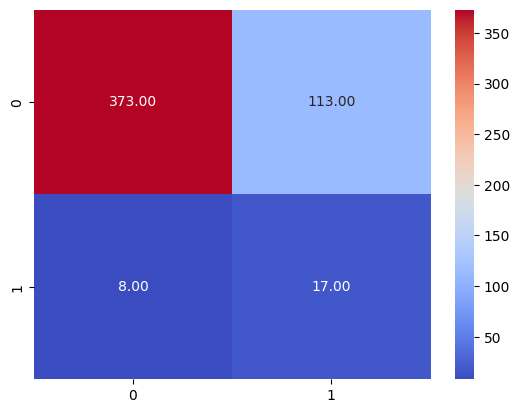

In [48]:


sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)


plt.show()

In [49]:
pip install xgboost lightgbm catboost

In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [51]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

In [52]:
from tqdm import tqdm

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[486   0]
 [ 25   0]]


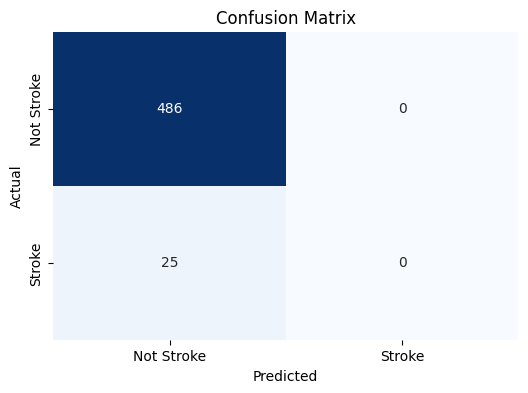


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       486
      Stroke       0.00      0.00      0.00        25

    accuracy                           0.95       511
   macro avg       0.48      0.50      0.49       511
weighted avg       0.90      0.95      0.93       511

ROC-AUC: 0.8


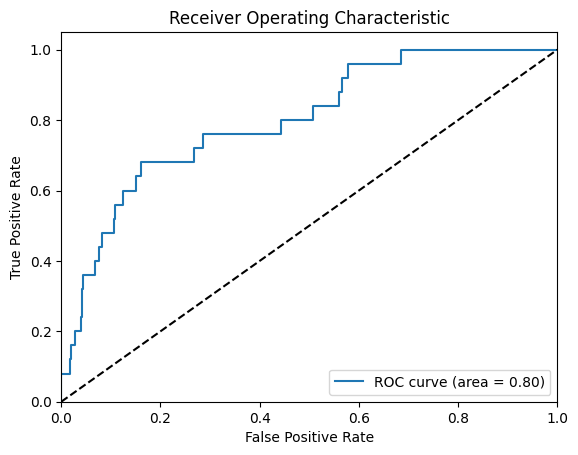

PR AUC: 0.2505803585440291


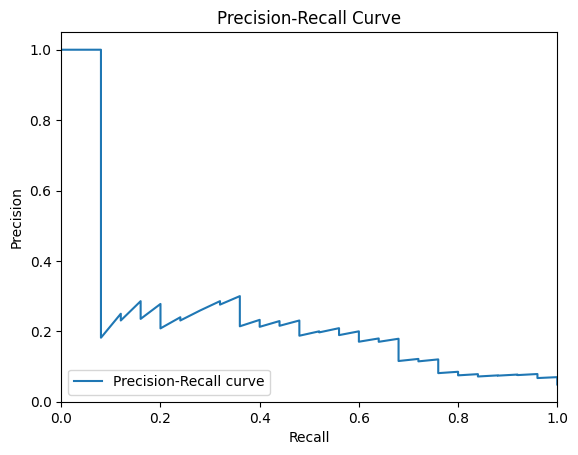

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
  8%|▊         | 1/13 [00:01<00:13,  1.10s/it]


Confusion Matrix:
 [[485   1]
 [ 25   0]]


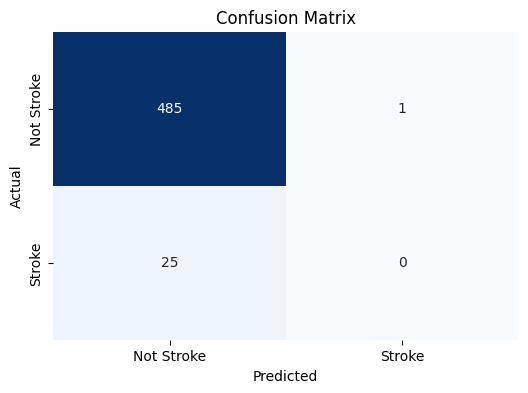


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       486
      Stroke       0.00      0.00      0.00        25

    accuracy                           0.95       511
   macro avg       0.48      0.50      0.49       511
weighted avg       0.90      0.95      0.93       511

ROC-AUC: 0.6292592592592592


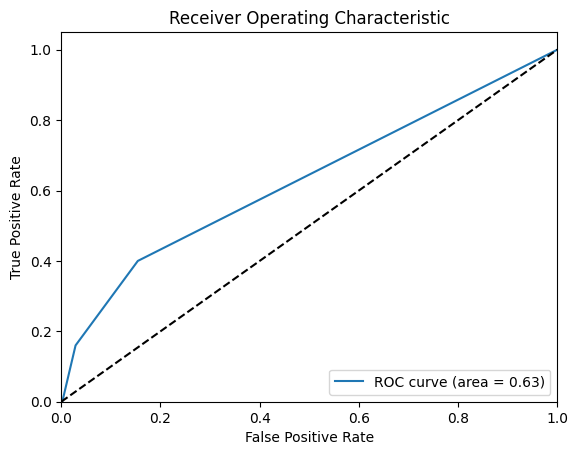

PR AUC: 0.09314505710960183


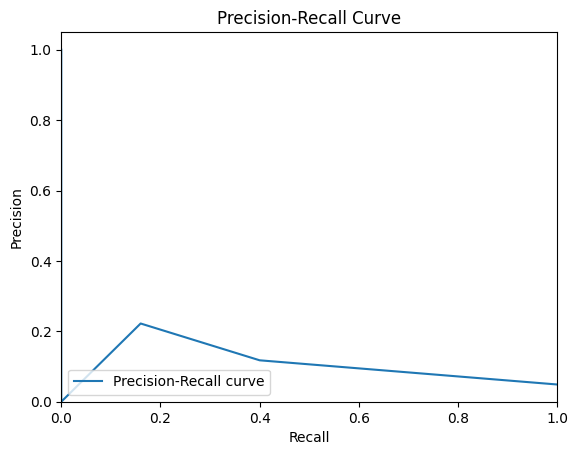

 15%|█▌        | 2/13 [00:01<00:10,  1.04it/s]


Confusion Matrix:
 [[486   0]
 [ 25   0]]


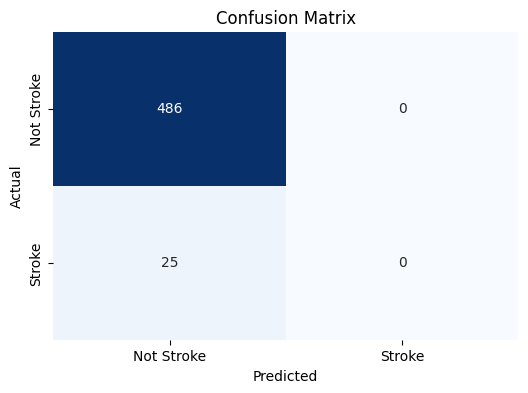


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       486
      Stroke       0.00      0.00      0.00        25

    accuracy                           0.95       511
   macro avg       0.48      0.50      0.49       511
weighted avg       0.90      0.95      0.93       511

ROC-AUC: 0.6442798353909466


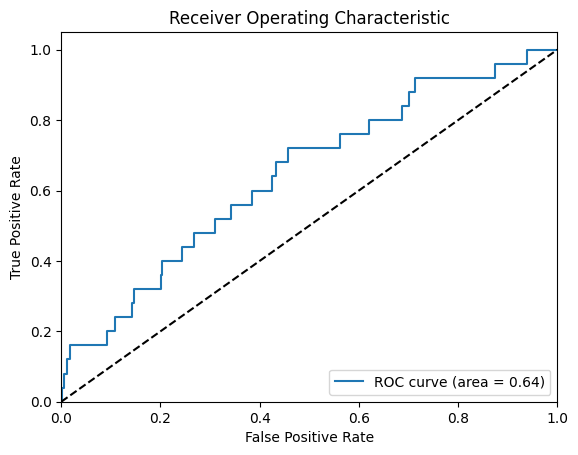

PR AUC: 0.12598085286990665


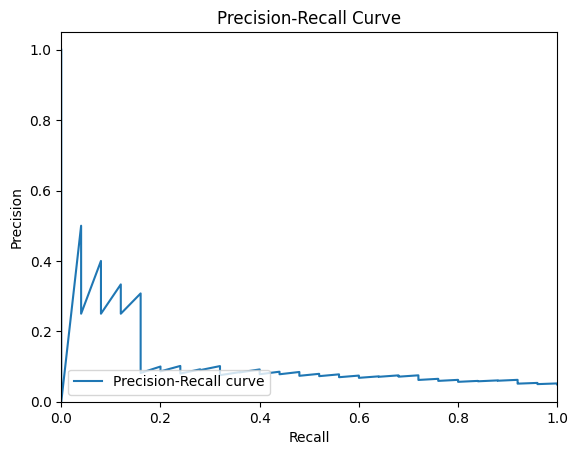

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
 23%|██▎       | 3/13 [00:14<01:00,  6.06s/it]


Confusion Matrix:
 [[468  18]
 [ 22   3]]


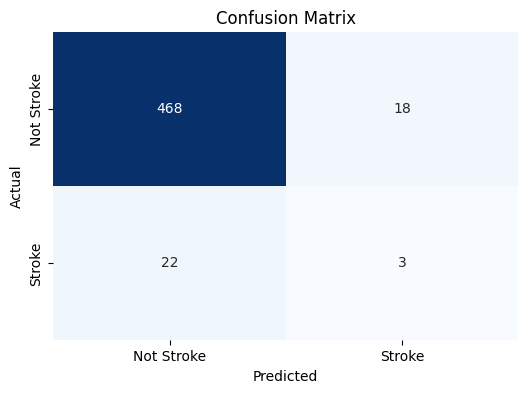


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      0.96      0.96       486
      Stroke       0.14      0.12      0.13        25

    accuracy                           0.92       511
   macro avg       0.55      0.54      0.54       511
weighted avg       0.92      0.92      0.92       511

ROC-AUC: 0.5414814814814816


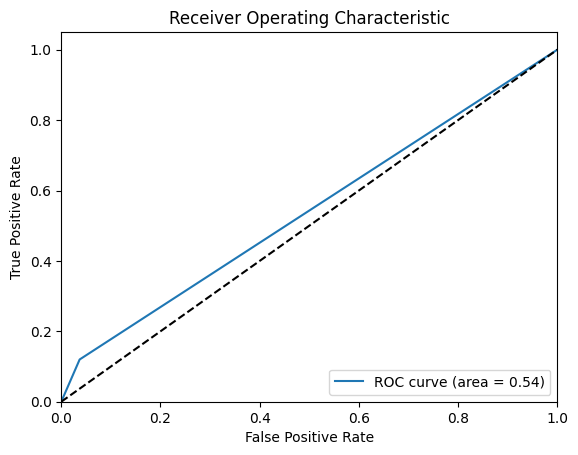

PR AUC: 0.060195694716242656


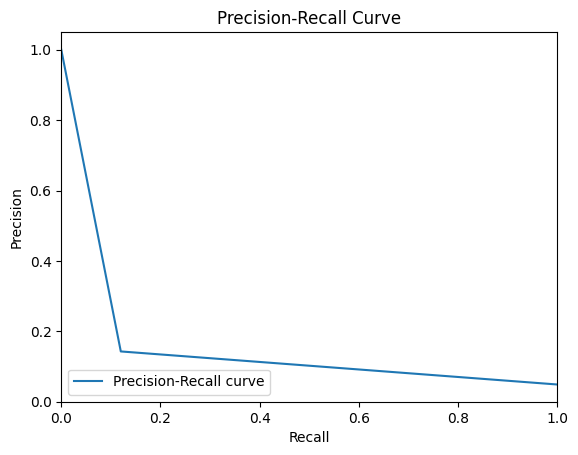

 31%|███       | 4/13 [00:16<00:40,  4.46s/it]


Confusion Matrix:
 [[437  49]
 [ 16   9]]


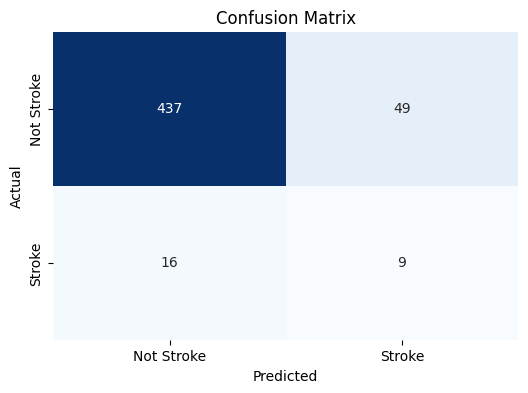


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      0.90      0.93       486
      Stroke       0.16      0.36      0.22        25

    accuracy                           0.87       511
   macro avg       0.56      0.63      0.57       511
weighted avg       0.93      0.87      0.90       511

ROC-AUC: 0.7645267489711934


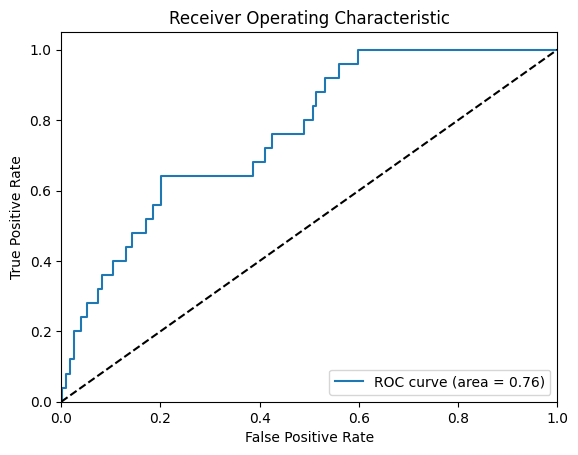

PR AUC: 0.16546706640181336


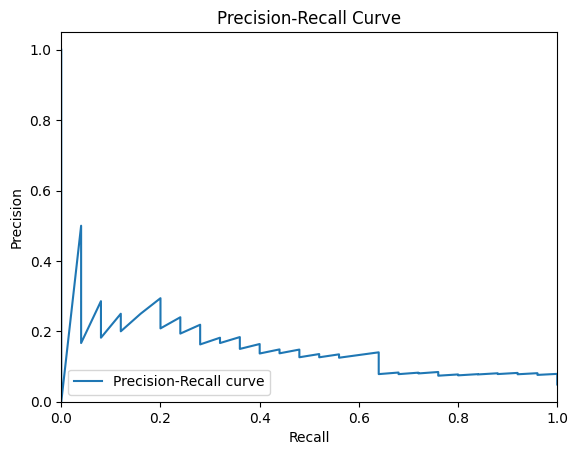

 38%|███▊      | 5/13 [00:18<00:30,  3.79s/it]


Confusion Matrix:
 [[485   1]
 [ 25   0]]


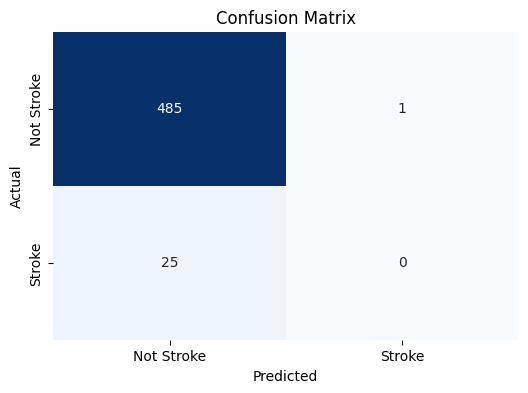


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       486
      Stroke       0.00      0.00      0.00        25

    accuracy                           0.95       511
   macro avg       0.48      0.50      0.49       511
weighted avg       0.90      0.95      0.93       511

ROC-AUC: 0.7321399176954733


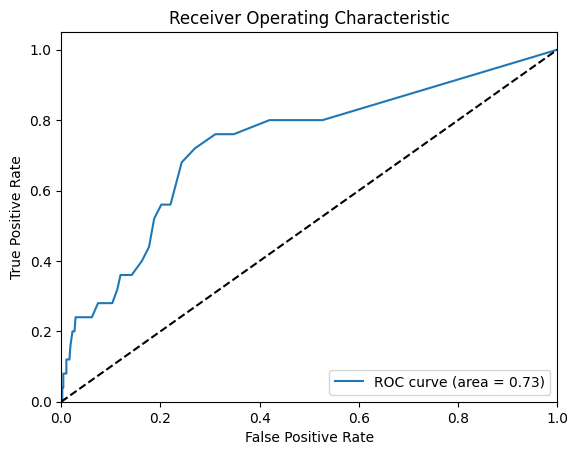

PR AUC: 0.1705723626141586


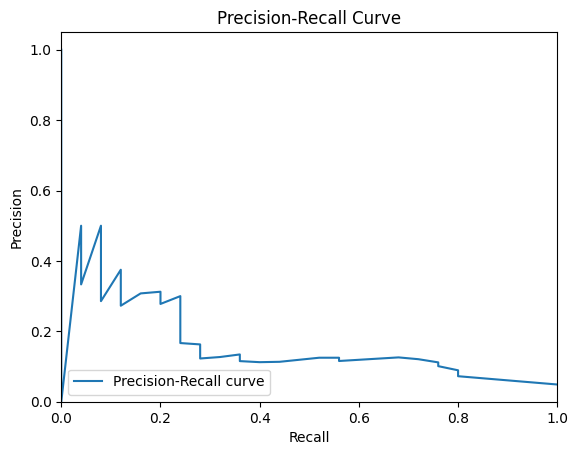

 46%|████▌     | 6/13 [00:22<00:26,  3.82s/it]


Confusion Matrix:
 [[484   2]
 [ 24   1]]


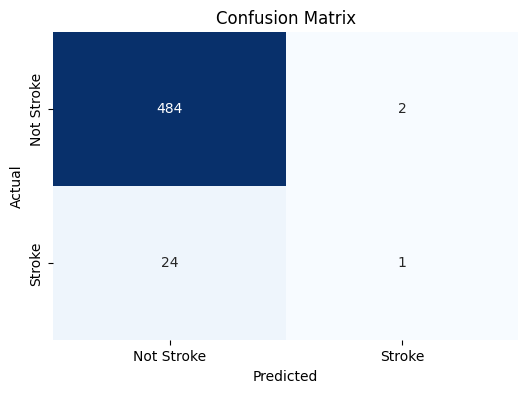


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       486
      Stroke       0.33      0.04      0.07        25

    accuracy                           0.95       511
   macro avg       0.64      0.52      0.52       511
weighted avg       0.92      0.95      0.93       511

ROC-AUC: 0.6831275720164609


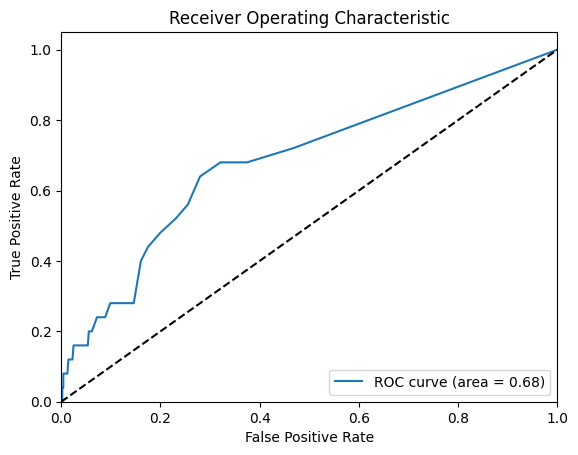

PR AUC: 0.13902499945337443


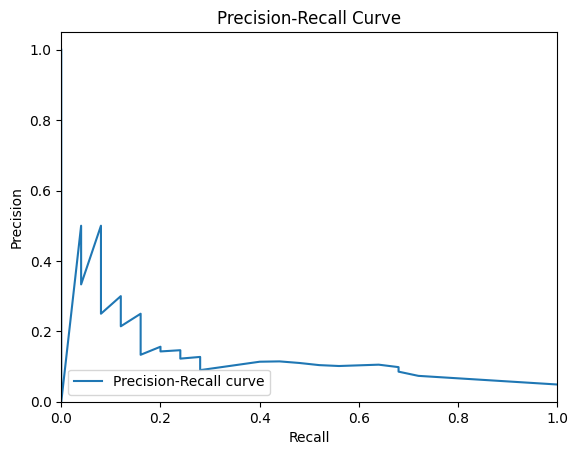

 54%|█████▍    | 7/13 [00:24<00:20,  3.33s/it]


Confusion Matrix:
 [[486   0]
 [ 25   0]]


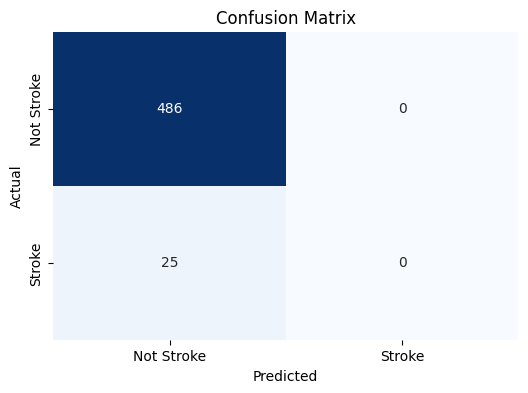


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       486
      Stroke       0.00      0.00      0.00        25

    accuracy                           0.95       511
   macro avg       0.48      0.50      0.49       511
weighted avg       0.90      0.95      0.93       511

ROC-AUC: 0.7844855967078189


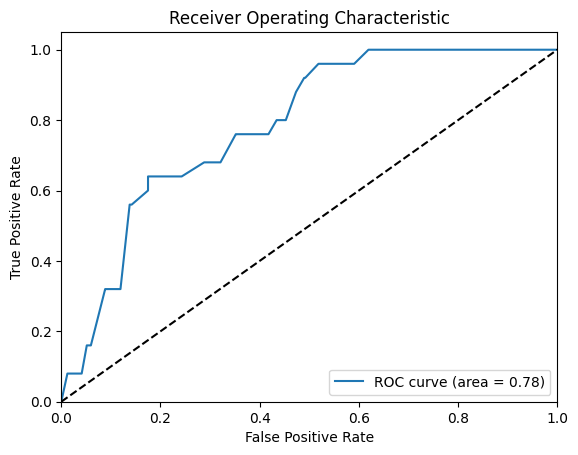

PR AUC: 0.14167937932499763


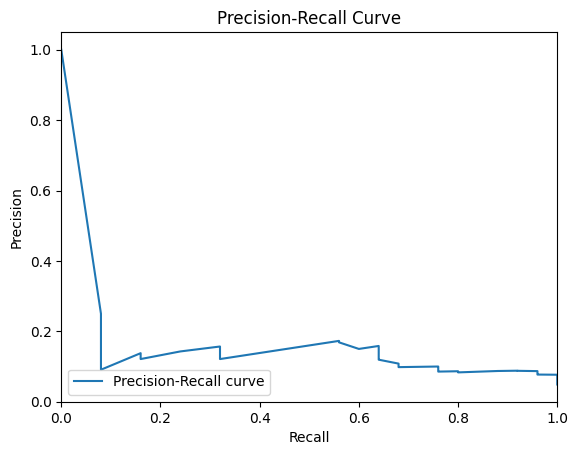

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
 62%|██████▏   | 8/13 [00:26<00:13,  2.80s/it]


Confusion Matrix:
 [[486   0]
 [ 24   1]]


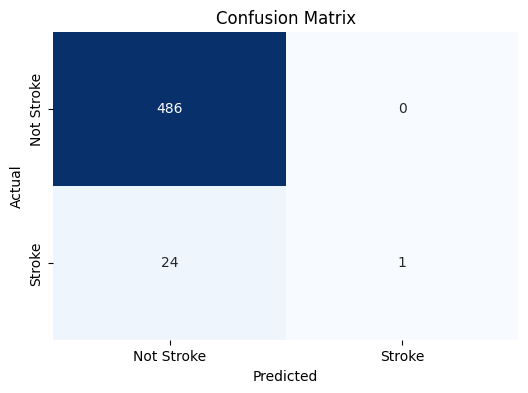


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.98       486
      Stroke       1.00      0.04      0.08        25

    accuracy                           0.95       511
   macro avg       0.98      0.52      0.53       511
weighted avg       0.96      0.95      0.93       511

ROC-AUC: 0.7974485596707819


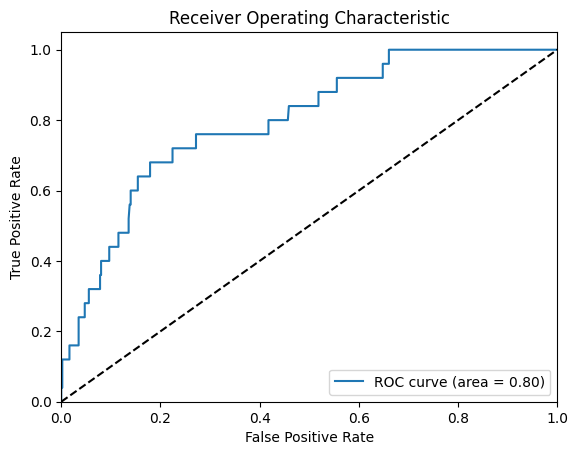

PR AUC: 0.24257206854655922


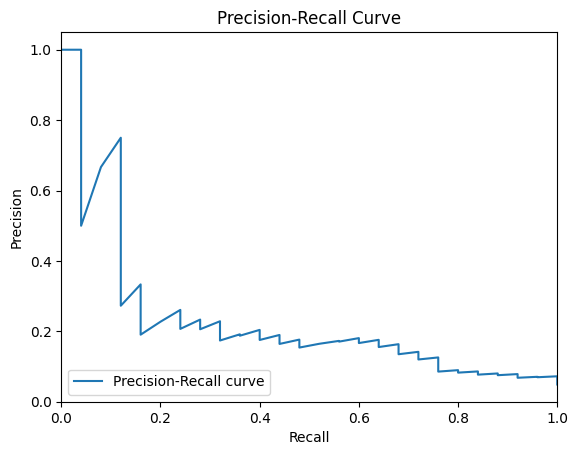

 69%|██████▉   | 9/13 [00:28<00:10,  2.58s/it]


Confusion Matrix:
 [[476  10]
 [ 23   2]]


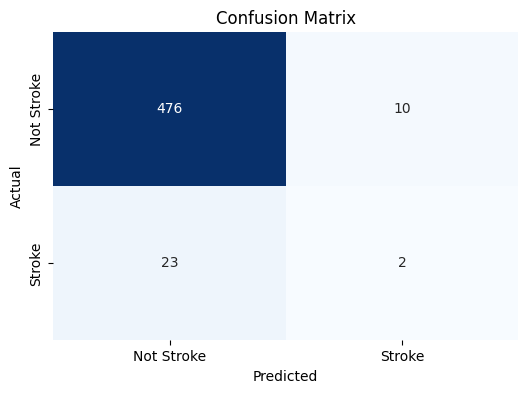


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.98      0.97       486
      Stroke       0.17      0.08      0.11        25

    accuracy                           0.94       511
   macro avg       0.56      0.53      0.54       511
weighted avg       0.92      0.94      0.92       511

ROC-AUC: 0.7962962962962963


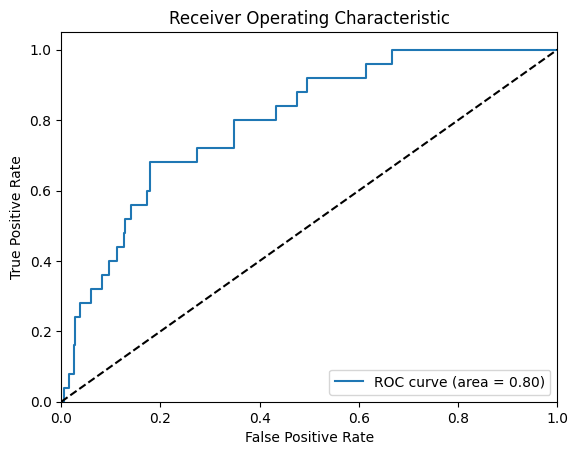

PR AUC: 0.1692536000042061


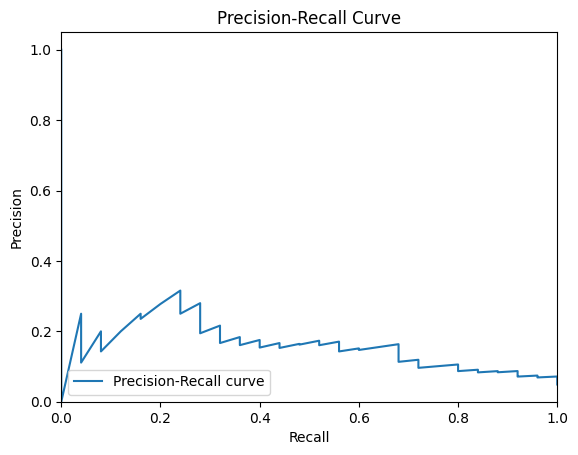

 77%|███████▋  | 10/13 [00:30<00:06,  2.33s/it]/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [12:33:34] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[476  10]
 [ 22   3]]


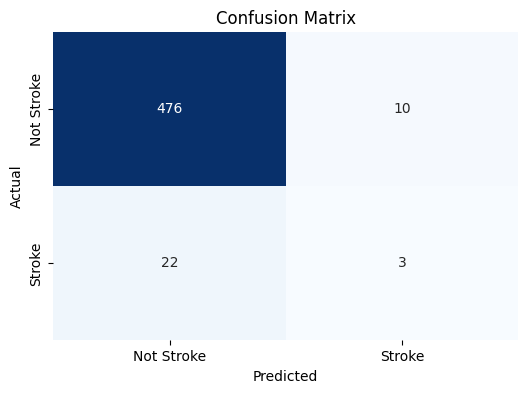


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      0.98      0.97       486
      Stroke       0.23      0.12      0.16        25

    accuracy                           0.94       511
   macro avg       0.59      0.55      0.56       511
weighted avg       0.92      0.94      0.93       511

ROC-AUC: 0.7734979423868313


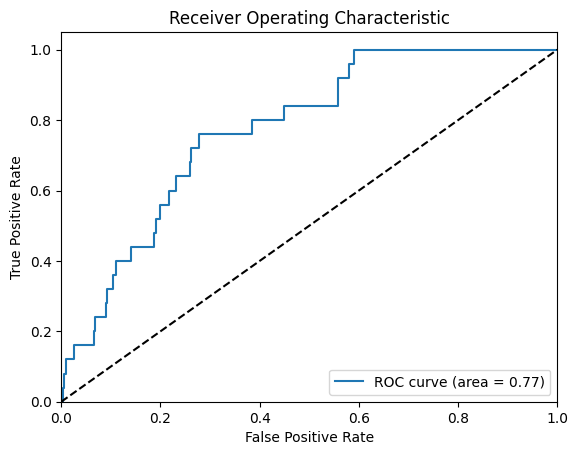

PR AUC: 0.15431996771607154


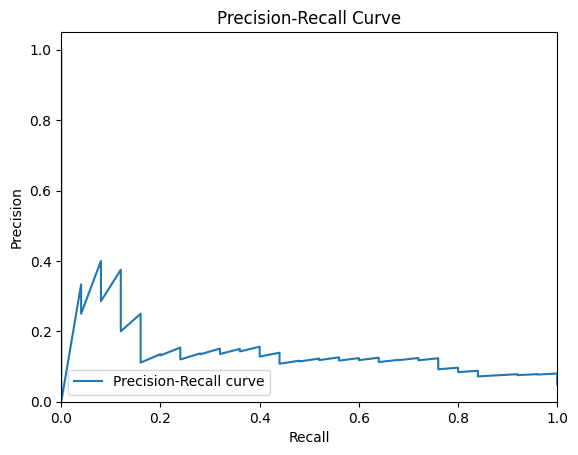

 85%|████████▍ | 11/13 [00:34<00:05,  2.92s/it]


Confusion Matrix:
 [[482   4]
 [ 23   2]]


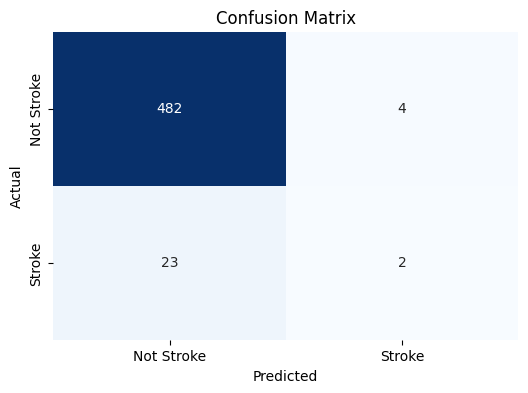


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       486
      Stroke       0.33      0.08      0.13        25

    accuracy                           0.95       511
   macro avg       0.64      0.54      0.55       511
weighted avg       0.92      0.95      0.93       511

ROC-AUC: 0.7971193415637859


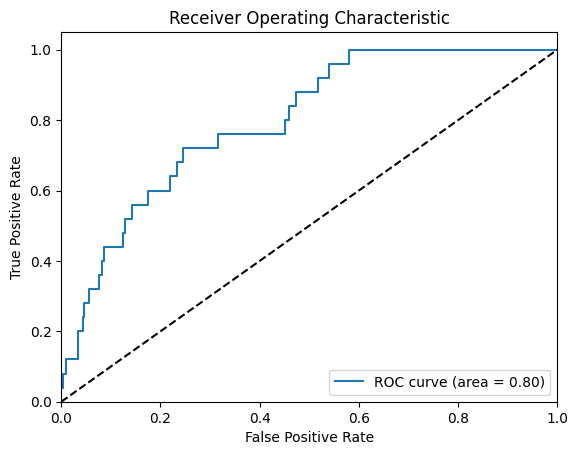

PR AUC: 0.21100964263972694


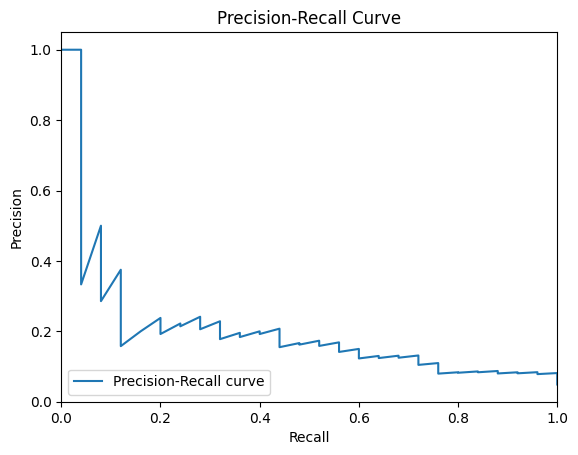

 92%|█████████▏| 12/13 [00:41<00:03,  3.96s/it]

[LightGBM] [Info] Number of positive: 224, number of negative: 4374
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002116 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 632
[LightGBM] [Info] Number of data points in the train set: 4598, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.048717 -> initscore=-2.971787
[LightGBM] [Info] Start training from score -2.971787

Confusion Matrix:
 [[481   5]
 [ 22   3]]


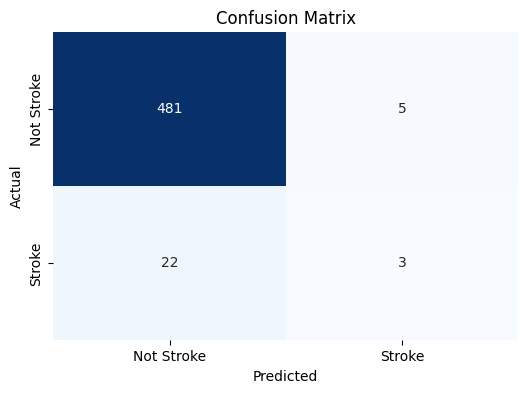


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      0.99      0.97       486
      Stroke       0.38      0.12      0.18        25

    accuracy                           0.95       511
   macro avg       0.67      0.55      0.58       511
weighted avg       0.93      0.95      0.93       511

ROC-AUC: 0.8010699588477366


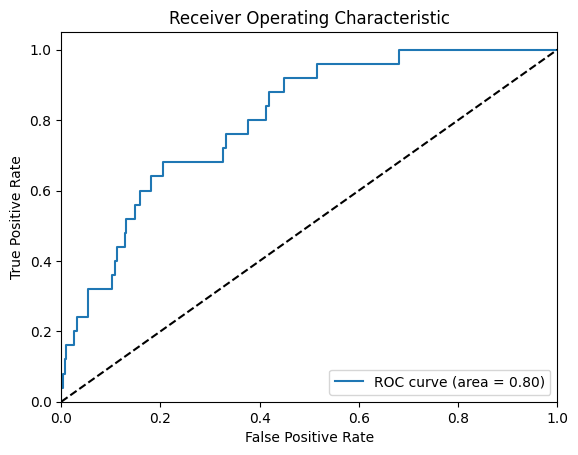

PR AUC: 0.2235047964532884


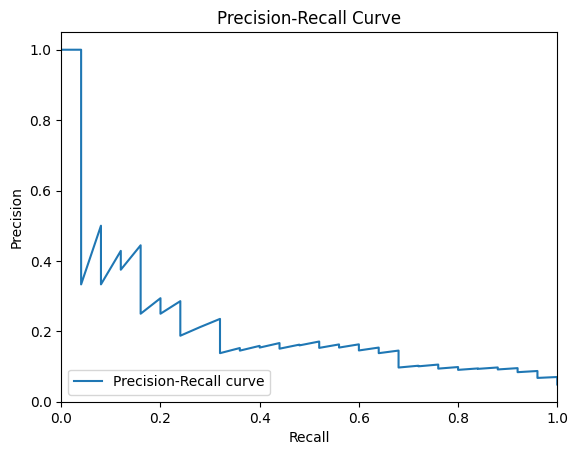

100%|██████████| 13/13 [00:42<00:00,  3.24s/it]


In [53]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(x_train, y_train)

    train_pred = model.predict(x_train)
    test_pred  = model.predict(x_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(x_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [12:34:59] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[480   6]
 [ 22   3]]


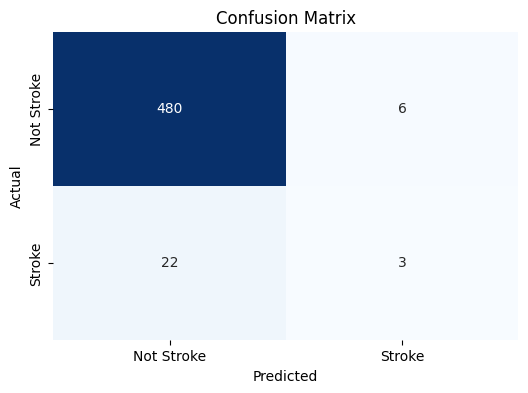


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      0.99      0.97       486
      Stroke       0.33      0.12      0.18        25

    accuracy                           0.95       511
   macro avg       0.64      0.55      0.57       511
weighted avg       0.93      0.95      0.93       511

ROC-AUC: 0.7768724279835391


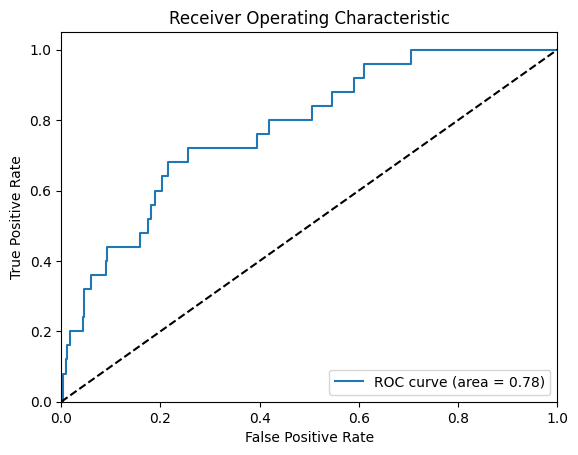

PR AUC: 0.1926358553294706


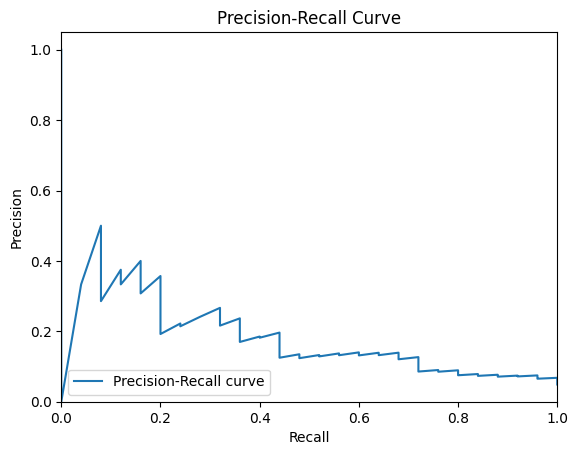

In [57]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(x_train, y_train)
voting_train_pred = voting_model.predict(x_train)
voting_test_pred = voting_model.predict(x_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = voting_model.predict_proba(x_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [12:36:24] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "max_iter" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[479   7]
 [ 25   0]]


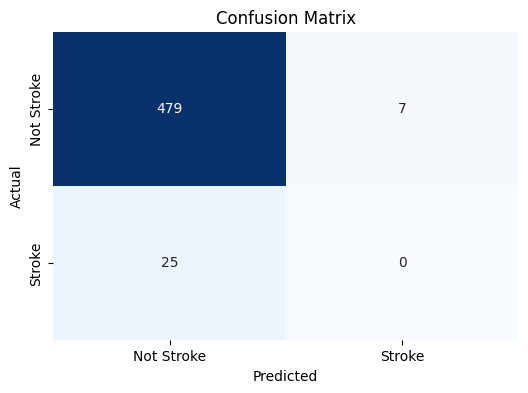


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       486
      Stroke       0.00      0.00      0.00        25

    accuracy                           0.94       511
   macro avg       0.48      0.49      0.48       511
weighted avg       0.90      0.94      0.92       511

ROC-AUC: 0.7104115226337449


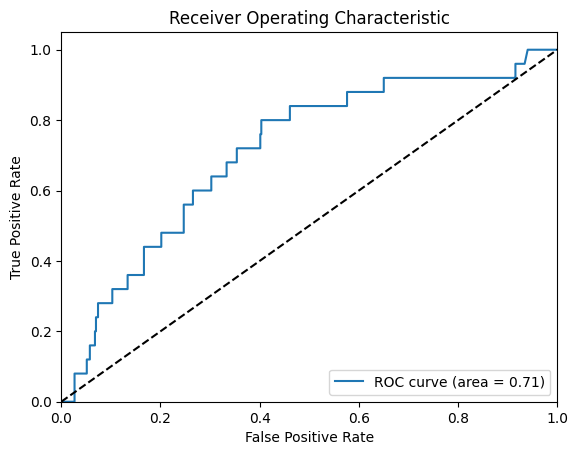

PR AUC: 0.1033782599964464


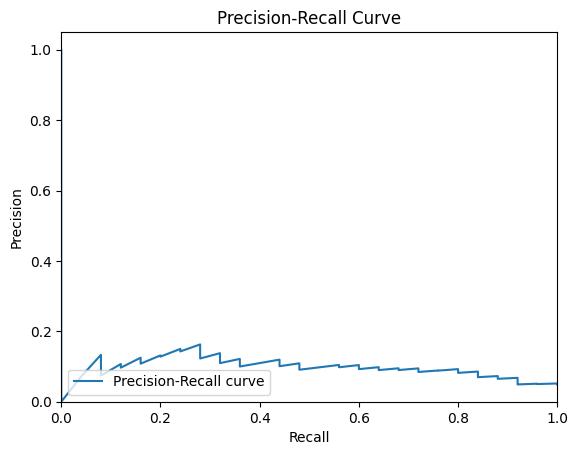

In [59]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),


    ],
    final_estimator=XGBClassifier(max_iter=2000),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(x_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(x_train)
stack_auto_test_pred  = stack_auto.predict(x_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(x_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [60]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Naive Bayes,0.864071,0.872798,0.154905,0.155172,0.401786,0.36,0.223602,0.216867,0.644766,0.629588,0.764527,0.165467
LightGBM,0.989126,0.947162,1.000000,0.375000,0.776786,0.12,0.874372,0.181818,0.888393,0.554856,0.801070,0.223505
Voting Classifier,0.971509,0.945205,1.000000,0.333333,0.415179,0.12,0.586751,0.176471,0.707589,0.553827,0.776872,0.192636
XGBoost,0.995433,0.937378,1.000000,0.230769,0.906250,0.12,0.950820,0.157895,0.953125,0.549712,0.773498,0.154320
Decision Tree,1.000000,0.921722,1.000000,0.142857,1.000000,0.12,1.000000,0.130435,1.000000,0.541481,0.541481,0.060196
CatBoost,0.973902,0.947162,1.000000,0.333333,0.464286,0.08,0.634146,0.129032,0.732143,0.535885,0.797119,0.211010
Hist Gradient Boosting,0.991301,0.935421,1.000000,0.166667,0.821429,0.08,0.901961,0.108108,0.910714,0.529712,0.796296,0.169254
Gradient Boosting,0.957373,0.953033,0.966667,1.000000,0.129464,0.04,0.228346,0.076923,0.564618,0.520000,0.797449,0.242572
Extra Trees,1.000000,0.949119,1.000000,0.333333,1.000000,0.04,1.000000,0.071429,1.000000,0.517942,0.683128,0.139025
KNN,0.952153,0.949119,0.666667,0.000000,0.035714,0.00,0.067797,0.000000,0.517400,0.498971,0.629259,0.093145


<Axes: >

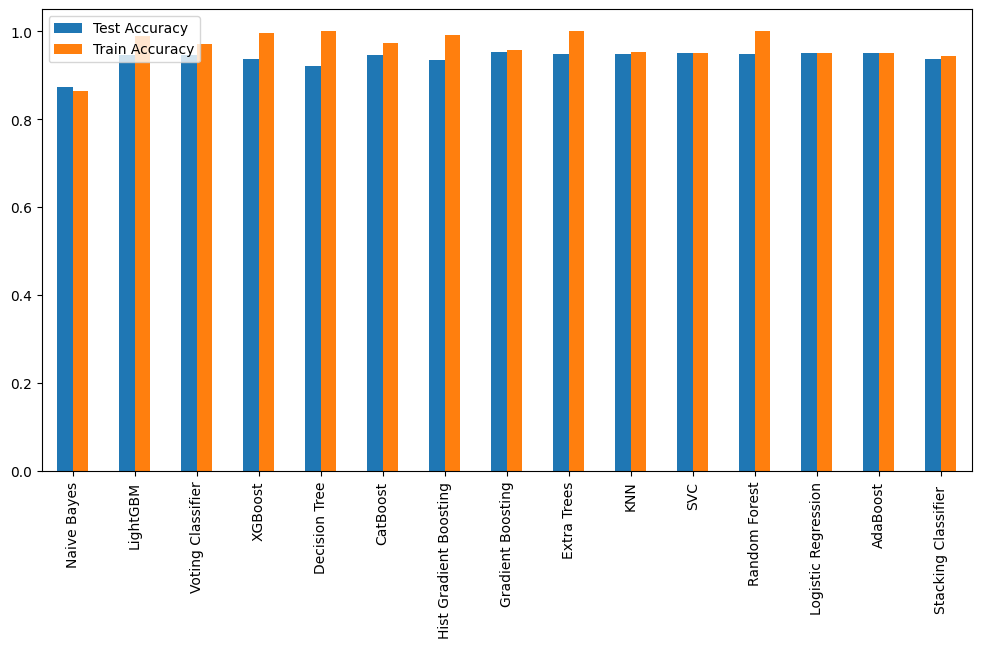

In [61]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

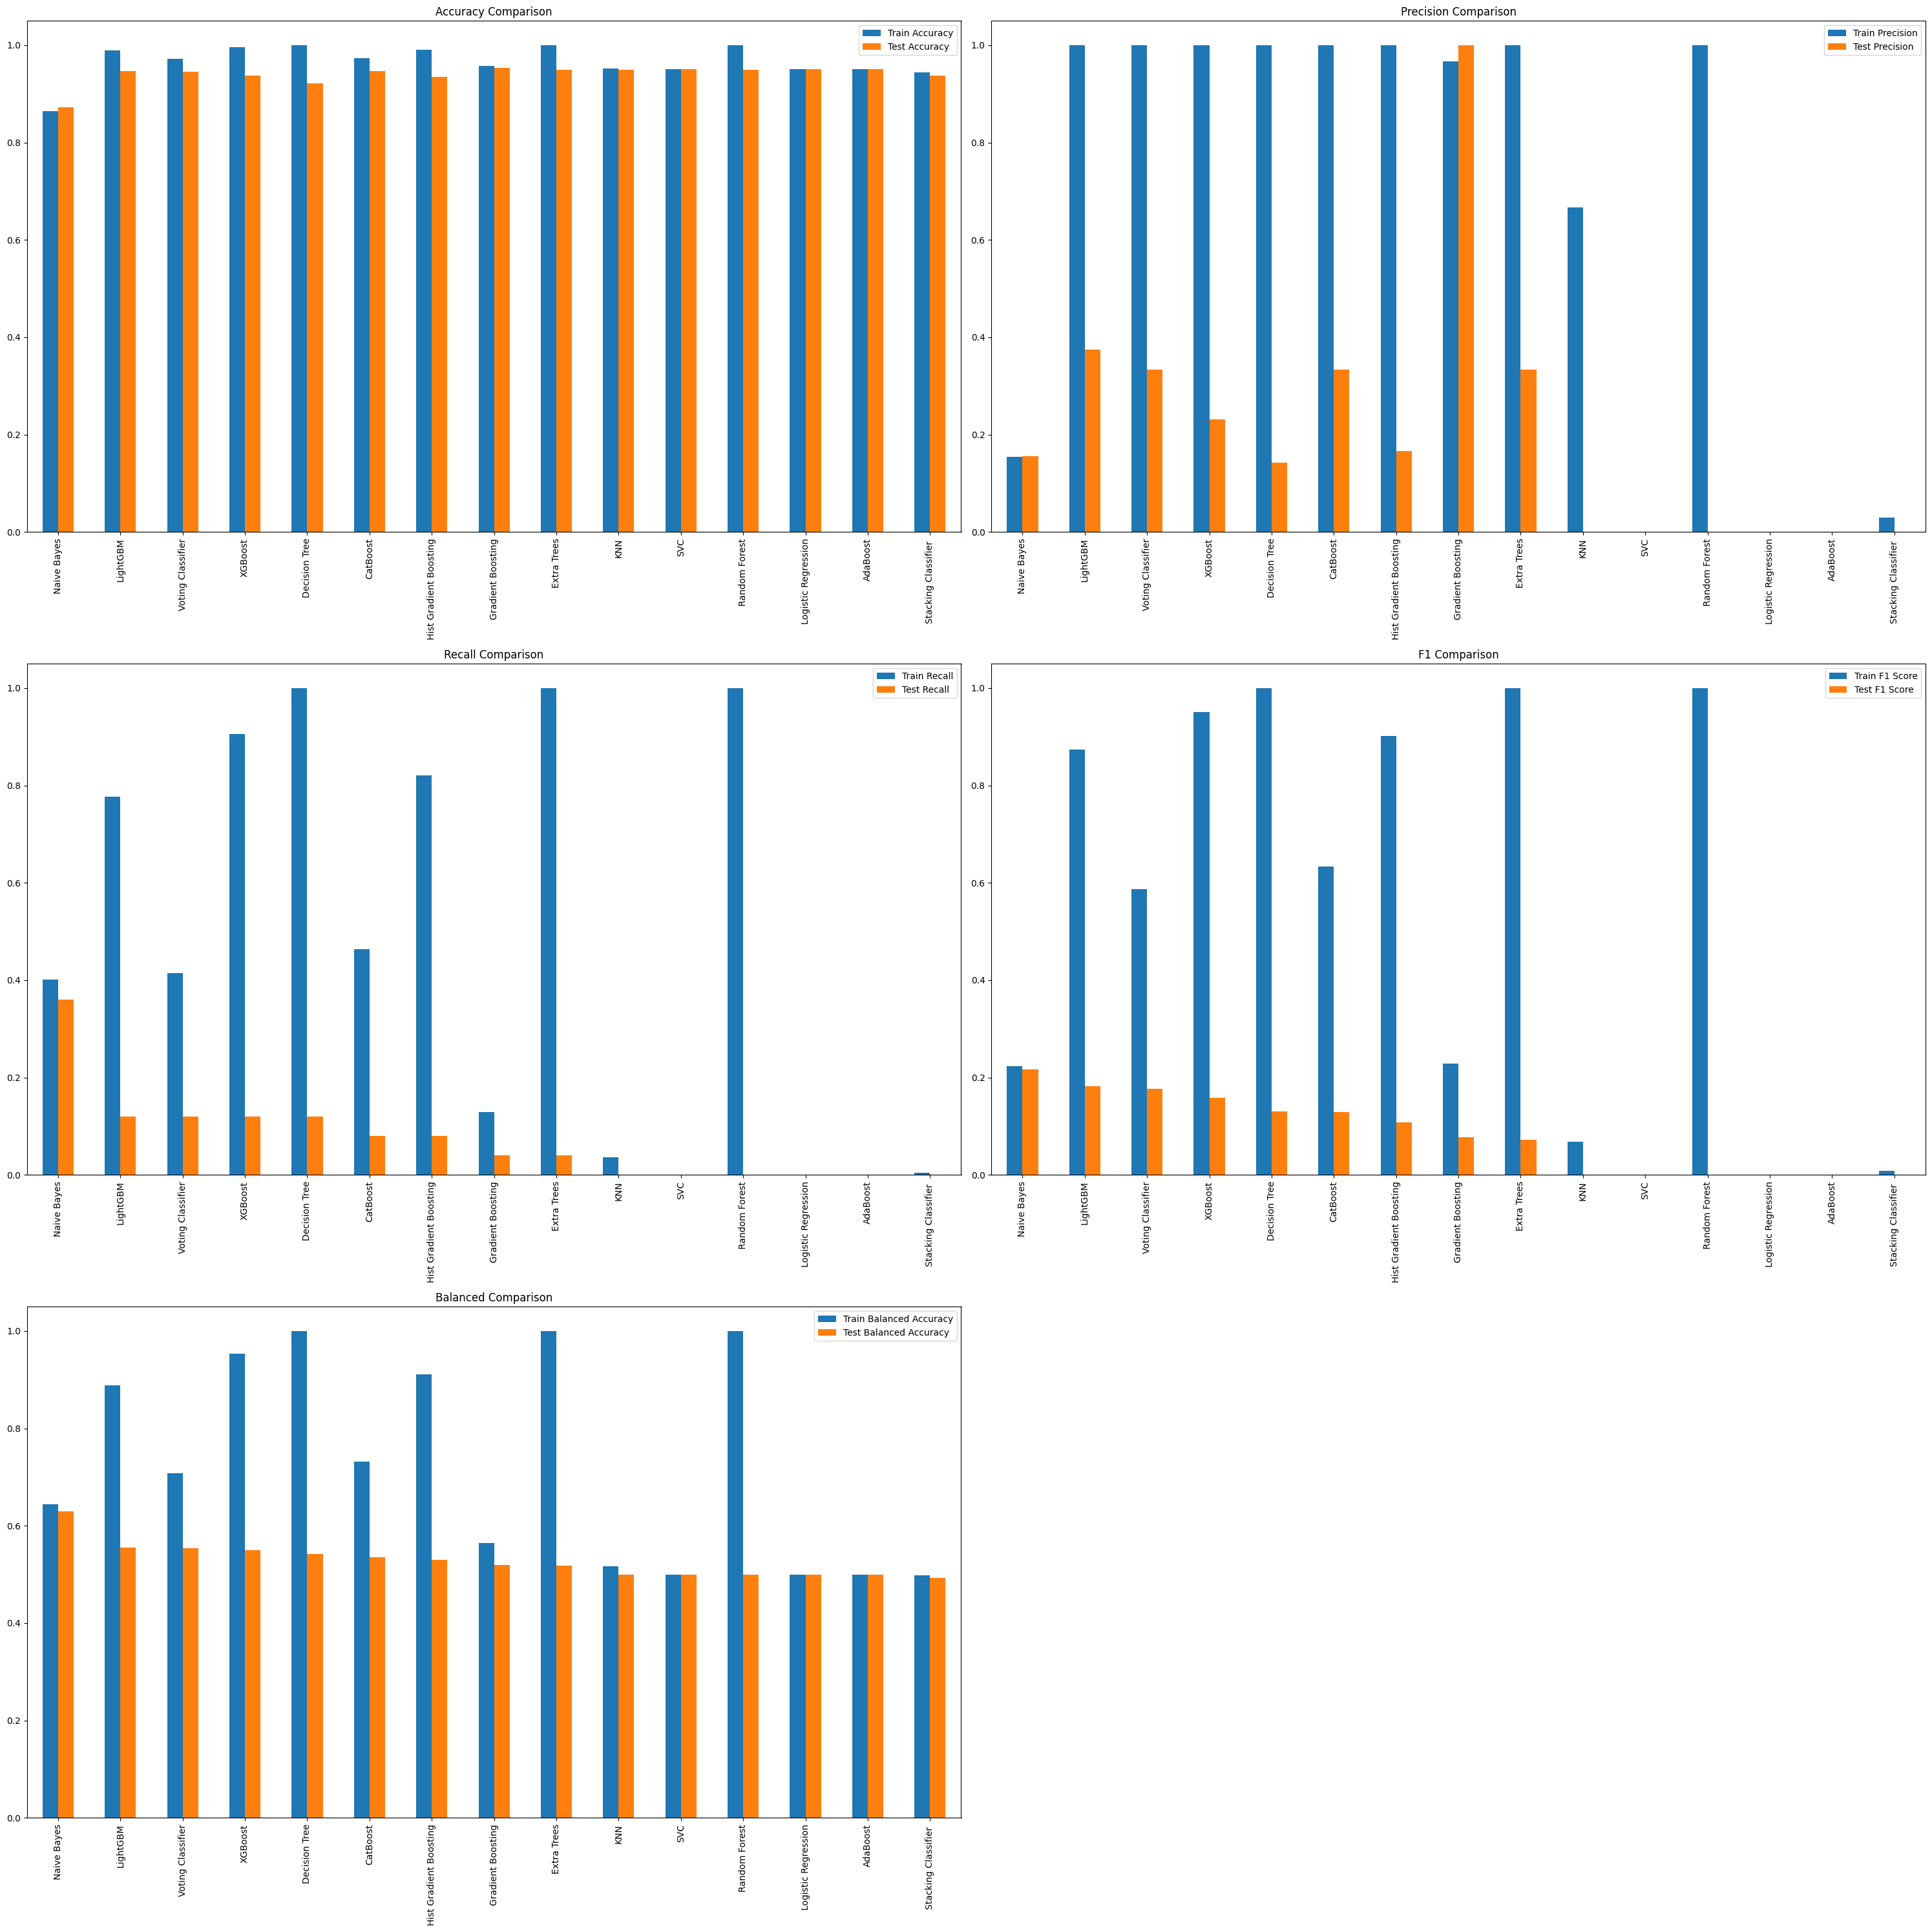

In [62]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()